# Notebook 6: Corrected two-instrument hedging with JEPA variance

## What was wrong in Notebook 4
1. **The loss could not teach hedging.** It had no learnable threshold, so it was nearly linear in terminal wealth. Hedging cannot change expected wealth (the stock is a martingale), so nothing rewarded risk reduction. This notebook uses a proper **CVaR / OCE loss with a learnable threshold** $w$:
$$\text{CVaR}_\alpha = \min_w \Big\{ w + \tfrac{1}{1-\alpha}\,\mathbb{E}[(-W_T - w)^+] \Big\}$$
2. **The sigmoid capped the variance-swap hedge at 1.** The analytical variance-swap delta is in variance-swap units and is far larger than 1. Outputs are now linear, and the variance-swap output is multiplied by a fixed data-driven scale.
3. **No option premium.** Terminal wealth is now $W_T = p_0 + \sum_t(\delta^1_t \Delta S_t + \delta^2_t \Delta L_t) - (S_T-K)^+$, with $p_0$ the Heston price from the COS pricer. The analytical hedge should then have mean wealth close to 0 and can be compared to Buehler's numbers.

## Variance swap vs variance
$L_t = \int_0^t V_s ds + \tfrac{V_t-\theta}{\kappa}(1-e^{-\kappa\tau}) + \theta\tau$ is a **tradable price**. Its increments $\Delta L_t$ are always the second hedging instrument. Its **level** is also a function of $V_t$, so including it as a state feature leaks volatility information into the "No-Vol" condition.

## Two variants
| Variant | State features |
|---|---|
| `clean` | $[\log S_t/S_0,\ V_t\text{-slot},\ \tau_t]$ where the $V_t$-slot is true $V$ (Oracle), JEPA $\hat V$ (JEPA), or absent (No-Vol) |
| `withL` | the same, plus the variance-swap level $L_t$ |

The `clean` variant is the fair test of "can JEPA's inferred variance replace true variance". Both are the same JEPA-vs-Oracle-vs-No-Vol comparison, so any difference between the variants is attributable to the $L_t$ feature.

## How to read the results
Compare against **Analytical Δ** and **Unhedged**, not only against the other neural nets. A neural hedger that doesn't beat Unhedged by a wide margin has not learned to hedge, and no JEPA conclusion can be drawn from it.

In [1]:
import sys, os, time
sys.path.insert(0, '..')
REPO_ROOT = os.path.join('..', 'deep-hedging-heston')
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import torch, torch.nn as nn
from torch.utils.data import DataLoader
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm

from heston_sim.generate import load_split
from jepa.dataset import HestonWindowDataset
from jepa.model import HestonJEPA
from deep_hedging_heston.parameters import HestonParameters
from deep_hedging_heston.pricers import heston_call_deltas, model_deltas_on_paths
from deep_hedging_heston.simulate import MarketPaths

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
RESULTS = '../results'
RUNS = os.path.join(RESULTS, 'hedging_runs')   # every finished model is saved here
os.makedirs(RUNS, exist_ok=True)
print('Device:', DEVICE)

C:\Users\USER\AppData\Roaming\Python\Python310\site-packages\google\api_core\_python_version_support.py:223: FutureWarning: You are using a non-supported Python version (3.10.20). Google will not post any further updates to google.api_core supporting this Python version. Please upgrade to the latest Python version, or at least Python 3.11, and then update google.api_core.
  warnings.warn(message, FutureWarning)


Device: cuda


In [2]:
# ---------------- configuration ----------------
ALPHA       = 0.5        # CVaR level (the repo's shipped model is alpha_50)
N_STEPS     = 15_000     # gradient steps per model (lower for a quick test, e.g. 3000)
BATCH       = 1024
LR          = 1e-3
N_UNITS     = 56
N_LAYERS    = 2
TRAIN_PATHS = 50_000
SEEDS       = [0]        # use [0, 1, 2] if you have time: gives error bars
VARIANTS    = {'clean': False, 'withL': True}   # name -> include variance-swap level in state?
CONTEXT_LEN, TARGET_LEN = 10, 5
BUEHLER_STD, BUEHLER_CVAR = 0.3808, 0.2433

## 1. Data, JEPA, probe, and inferred variance

In [3]:
train_data = load_split('train', '../data')
te = load_split('test', '../data')
hp = HestonParameters()
T = hp.timesteps

tr_idx = np.random.default_rng(1).choice(train_data['stocks'].shape[0], TRAIN_PATHS, replace=False)
tr = {k: v[tr_idx] for k, v in train_data.items()}
print(f'train paths {tr["stocks"].shape}   test paths {te["stocks"].shape}   timesteps {T}')

# ---- JEPA + linear probe (same recipe as the volatility probe) ----
ckpt = torch.load('../checkpoints/jepa_prices.pt', map_location=DEVICE, weights_only=False)
cfg = ckpt['config']
assert cfg['context_len'] == CONTEXT_LEN, 'CONTEXT_LEN must match the trained JEPA'
jepa = HestonJEPA(feature_dim=cfg['feature_dim'], d_model=cfg['d_model'], n_heads=cfg['n_heads'],
                  n_layers=cfg['n_layers'], ema_momentum=cfg['ema_momentum'],
                  var_reg_coeff=cfg['var_reg_coeff']).to(DEVICE)
jepa.load_state_dict(ckpt['model_state']); jepa.eval()

sub = np.random.default_rng(42).choice(train_data['log_returns'].shape[0], 50_000, replace=False)
ds = HestonWindowDataset({k: v[sub] for k, v in train_data.items()}, CONTEXT_LEN, TARGET_LEN, 'prices')
Z, V = [], []
with torch.no_grad():
    for b in tqdm(DataLoader(ds, batch_size=2048, shuffle=False), desc='Encoding for probe'):
        Z.append(jepa.encode(b['context'].to(DEVICE)).cpu().numpy())
        V.append(b['target_variance'].numpy())
Z, V = np.concatenate(Z), np.concatenate(V)
scaler = StandardScaler(); probe = Ridge(alpha=1.0)
probe.fit(scaler.fit_transform(Z), V)
V_FALLBACK = float(V.mean())   # used for the first CONTEXT_LEN steps (no full window yet)
print('probe fitted')

def infer_variance(log_returns, bs=4096):
    N, T_ = log_returns.shape
    out = np.full((N, T_ + 1), V_FALLBACK, dtype=np.float32)
    for t in range(CONTEXT_LEN, T_ + 1):
        ctx = log_returns[:, t - CONTEXT_LEN:t][:, :, None]
        preds = []
        for s in range(0, N, bs):
            with torch.no_grad():
                z = jepa.encode(torch.tensor(ctx[s:s+bs], dtype=torch.float32).to(DEVICE)).cpu().numpy()
            preds.append(np.clip(probe.predict(scaler.transform(z)), 0, None))
        out[:, t] = np.concatenate(preds)
    return out

# cached so a restart does not redo this
f_tr, f_te = os.path.join(RESULTS, 'v_jepa_train.npy'), os.path.join(RESULTS, 'v_jepa_test.npy')
if os.path.exists(f_tr) and os.path.exists(f_te):
    V_JEPA_TR, V_JEPA_TE = np.load(f_tr), np.load(f_te)
    print('loaded cached JEPA variance')
else:
    V_JEPA_TR = infer_variance(tr['log_returns']); V_JEPA_TE = infer_variance(te['log_returns'])
    np.save(f_tr, V_JEPA_TR); np.save(f_te, V_JEPA_TE)

m = slice(CONTEXT_LEN, None)
print('R2 of JEPA variance vs true variance on test (t >= CONTEXT_LEN):',
      round(r2_score(te['variance'][:, m].ravel(), V_JEPA_TE[:, m].ravel()), 4))

train paths (50000, 31)   test paths (50000, 31)   timesteps 30


c:\Users\USER\OneDrive\Desktop\IIT\Thesis\Implementation\Git Repo\JEPA---Deep-Hedging\Vibe coded experiment 2\Jepa-Heston\notebooks\..\jepa\encoder.py:94: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


Encoding for probe:   0%|          | 0/391 [00:00<?, ?it/s]

probe fitted
R2 of JEPA variance vs true variance on test (t >= CONTEXT_LEN): 0.7641


## 2. Benchmarks and sanity checks
Run this before training anything. These numbers define what "good" means.

In [4]:
# Option premium p0 from the COS pricer (state at t=0: S0, v0, tau=T)
price0, _, _ = heston_call_deltas(np.array([hp.S0]), np.array([hp.v0]), hp.T, hp)
PREMIUM = float(price0[0])

def metrics(W, alpha=ALPHA):
    L = np.sort(-W)
    return dict(mean=float(W.mean()), std=float(W.std()), cvar=float(L[int(alpha * len(L)):].mean()))

dS_te_np = (te['stocks'][:, 1:] - te['stocks'][:, :-1]).astype(np.float64)
dL_te_np = (te['variance_swap'][:, 1:] - te['variance_swap'][:, :-1]).astype(np.float64)

W_unhedged = PREMIUM - te['payoff']
mkt = MarketPaths(Stocks=te['stocks'], Variance=te['variance'],
                  Variance_swap=te['variance_swap'], Payoff=te['payoff'])
d1_an, d2_an = model_deltas_on_paths(mkt, hp)
W_analytical = PREMIUM + (d1_an * dS_te_np + d2_an * dL_te_np).sum(1) - te['payoff']

print(f'Premium p0 (Heston price at t=0): {PREMIUM:.4f}')
print(f'Analytical delta1 range: [{d1_an.min():.3f}, {d1_an.max():.3f}]')
print(f'Analytical delta2 range: [{d2_an.min():.1f}, {d2_an.max():.1f}]   <- far outside (0,1): this is why a sigmoid could not work')
for name, W in [('Unhedged', W_unhedged), ('Analytical', W_analytical)]:
    mm = metrics(W)
    print(f'{name:<11} mean={mm["mean"]:+.4f}  std={mm["std"]:.4f}  CVaR{int(ALPHA*100)}={mm["cvar"]:.4f}')
print(f'Buehler ref  std={BUEHLER_STD}  CVaR={BUEHLER_CVAR}')

# Output scale for the variance-swap leg: ratio of instrument volatilities (data only, no pricer)
dS_tr_np = tr['stocks'][:, 1:] - tr['stocks'][:, :-1]
dL_tr_np = tr['variance_swap'][:, 1:] - tr['variance_swap'][:, :-1]
D2_SCALE = float(dS_tr_np.std() / dL_tr_np.std())
print(f'D2_SCALE = {D2_SCALE:.2f}')

Premium p0 (Heston price at t=0): 1.6918
Analytical delta1 range: [-0.099, 1.092]
Analytical delta2 range: [-860.4, 4065.3]   <- far outside (0,1): this is why a sigmoid could not work
Unhedged    mean=+0.0005  std=2.1635  CVaR50=1.4718
Analytical  mean=-0.0021  std=0.3739  CVaR50=0.2412
Buehler ref  std=0.3808  CVaR=0.2433
D2_SCALE = 1032.36


**Check before continuing:** Analytical mean should be near 0, its std near 0.37, and its CVaR near 0.24. Unhedged std should be about 2.1. If not, stop here and tell me.

## 3. Network, loss, training

In [5]:
class Hedger(nn.Module):
    # Buehler-style feed-forward hedger: tanh, 2 layers, 56 units. Linear outputs (no sigmoid).
    # Input: normalised state + previous raw outputs. Output: [delta_stock, delta_varswap].
    def __init__(self, in_dim, d2_scale, n_units=N_UNITS, n_layers=N_LAYERS):
        super().__init__()
        layers = [nn.Linear(in_dim + 2, n_units), nn.Tanh()]
        for _ in range(n_layers - 1):
            layers += [nn.Linear(n_units, n_units), nn.Tanh()]
        layers += [nn.Linear(n_units, 2)]
        self.net = nn.Sequential(*layers)
        self.d2_scale = d2_scale
        self.w = nn.Parameter(torch.zeros(()))      # learnable CVaR threshold

    def forward(self, x, prev_raw):
        raw = self.net(torch.cat([x, prev_raw], dim=-1))
        delta = torch.stack([raw[:, 0], raw[:, 1] * self.d2_scale], dim=-1)
        return raw, delta


def terminal_wealth(net, X, dS, dL, payoff):
    N, T_, _ = X.shape
    prev = torch.zeros(N, 2, device=X.device)
    pnl = torch.zeros(N, device=X.device)
    for t in range(T_):
        raw, d = net(X[:, t, :], prev)
        pnl = pnl + d[:, 0] * dS[:, t] + d[:, 1] * dL[:, t]
        prev = raw
    return PREMIUM + pnl - payoff


def cvar_loss(W, w, alpha):
    # Rockafellar-Uryasev form of CVaR on losses L = -W, with learnable threshold w
    return w + torch.relu(-W - w).mean() / (1.0 - alpha)


def train_one(X, dS, dL, payoff, label, seed):
    torch.manual_seed(seed)
    net = Hedger(X.shape[-1], D2_SCALE).to(DEVICE)
    opt = torch.optim.Adam([{'params': net.net.parameters(), 'lr': LR},
                            {'params': [net.w], 'lr': 1e-2}])
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=N_STEPS)
    g = torch.Generator().manual_seed(seed)
    n = X.shape[0]
    hist, run = [], []
    pbar = tqdm(range(N_STEPS), desc=label)
    for step in pbar:
        idx = torch.randint(0, n, (BATCH,), generator=g).to(DEVICE)
        W = terminal_wealth(net, X[idx], dS[idx], dL[idx], payoff[idx])
        loss = cvar_loss(W, net.w, ALPHA)
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(net.parameters(), 1.0)
        opt.step(); sch.step()
        run.append(loss.item())
        if (step + 1) % 200 == 0:
            hist.append(float(np.mean(run))); run = []
            pbar.set_postfix({'CVaR': f'{hist[-1]:.4f}'})
    return net, np.array(hist)


def eval_W(net, X, dS, dL, payoff, bs=25_000):
    net.eval(); out = []
    with torch.no_grad():
        for s in range(0, X.shape[0], bs):
            out.append(terminal_wealth(net, X[s:s+bs], dS[s:s+bs], dL[s:s+bs], payoff[s:s+bs]).cpu().numpy())
    return np.concatenate(out)
print('defined')

defined


## 4. Run all conditions
Each finished model is saved to `results/hedging_runs/`. If you stop the notebook, re-running this cell **skips finished models** and carries on.

In [6]:
def build_features(stocks, v_in, ls, include_L):
    N, T1 = stocks.shape; T_ = T1 - 1
    tau = np.broadcast_to((hp.T - hp.dt * np.arange(T_)).astype(np.float32), (N, T_))
    cols = [np.log(stocks[:, :T_] / hp.S0)]
    if v_in is not None:
        cols.append(v_in[:, :T_])
    if include_L:
        cols.append(ls[:, :T_])
    cols.append(tau)
    return np.stack(cols, -1).astype(np.float32)

def v_for(cond, split):
    if cond == 'oracle': return (tr if split == 'tr' else te)['variance']
    if cond == 'jepa':   return V_JEPA_TR if split == 'tr' else V_JEPA_TE
    return None   # novol

def to_t(a): return torch.tensor(np.ascontiguousarray(a), dtype=torch.float32, device=DEVICE)

dS_tr, dL_tr, pay_tr = to_t(dS_tr_np), to_t(dL_tr_np), to_t(tr['payoff'])
dS_te, dL_te, pay_te = to_t(dS_te_np), to_t(dL_te_np), to_t(te['payoff'])

CONDITIONS = ['oracle', 'jepa', 'novol']
for vname, incL in VARIANTS.items():
    for cond in CONDITIONS:
        Ftr = build_features(tr['stocks'], v_for(cond, 'tr'), tr['variance_swap'], incL)
        Fte = build_features(te['stocks'], v_for(cond, 'te'), te['variance_swap'], incL)
        mu, sd = Ftr.reshape(-1, Ftr.shape[-1]).mean(0), Ftr.reshape(-1, Ftr.shape[-1]).std(0) + 1e-8
        Xtr, Xte = to_t((Ftr - mu) / sd), to_t((Fte - mu) / sd)
        for seed in SEEDS:
            key = f'{vname}_{cond}_s{seed}'
            wpath = os.path.join(RUNS, key + '_W.npy')
            if os.path.exists(wpath):
                print('skip (done):', key); continue
            net, hist = train_one(Xtr, dS_tr, dL_tr, pay_tr, key, seed)
            W = eval_W(net, Xte, dS_te, dL_te, pay_te)
            np.save(wpath, W); np.save(os.path.join(RUNS, key + '_hist.npy'), hist)
            mm = metrics(W)
            print(f'{key}: mean={mm["mean"]:+.4f} std={mm["std"]:.4f} CVaR={mm["cvar"]:.4f}')

clean_oracle_s0:   0%|          | 0/15000 [00:00<?, ?it/s]

clean_oracle_s0: mean=-0.0020 std=0.3860 CVaR=0.2431


clean_jepa_s0:   0%|          | 0/15000 [00:00<?, ?it/s]

clean_jepa_s0: mean=-0.0038 std=0.5478 CVaR=0.3387


clean_novol_s0:   0%|          | 0/15000 [00:00<?, ?it/s]

clean_novol_s0: mean=-0.0034 std=0.5593 CVaR=0.3431


... (2 outputs left out)

withL_jepa_s0:   0%|          | 0/15000 [00:00<?, ?it/s]

withL_jepa_s0: mean=-0.0025 std=0.4077 CVaR=0.2531


withL_novol_s0:   0%|          | 0/15000 [00:00<?, ?it/s]

withL_novol_s0: mean=-0.0025 std=0.4047 CVaR=0.2534


## 5. Results

In [7]:
def load_runs(vname, cond):
    Ws = []
    for seed in SEEDS:
        p = os.path.join(RUNS, f'{vname}_{cond}_s{seed}_W.npy')
        if os.path.exists(p): Ws.append(np.load(p))
    return Ws

summary = {}
for vname in VARIANTS:
    print('\n' + '=' * 78)
    print(f'VARIANT: {vname}   (VarSwap level in state: {VARIANTS[vname]})')
    print('=' * 78)
    print(f'{"Method":<22}{"mean":>9}{"std":>9}{"CVaR":>9}   (CVaR across seeds: sd)')
    rows = {}
    for cond in CONDITIONS:
        Ws = load_runs(vname, cond)
        if not Ws: continue
        ms = [metrics(W) for W in Ws]
        rows[cond] = dict(mean=np.mean([x['mean'] for x in ms]), std=np.mean([x['std'] for x in ms]),
                          cvar=np.mean([x['cvar'] for x in ms]), cvar_sd=np.std([x['cvar'] for x in ms]))
        r = rows[cond]
        print(f'{cond:<22}{r["mean"]:>+9.4f}{r["std"]:>9.4f}{r["cvar"]:>9.4f}   sd={r["cvar_sd"]:.4f}')
    for name, W in [('analytical', W_analytical), ('unhedged', W_unhedged)]:
        mm = metrics(W); rows[name] = dict(mean=mm['mean'], std=mm['std'], cvar=mm['cvar'], cvar_sd=0.0)
        print(f'{name:<22}{mm["mean"]:>+9.4f}{mm["std"]:>9.4f}{mm["cvar"]:>9.4f}')
    print(f'{"Buehler reference":<22}{"":>9}{BUEHLER_STD:>9.4f}{BUEHLER_CVAR:>9.4f}')
    summary[vname] = rows

    if all(c in rows for c in CONDITIONS):
        gap = rows['novol']['cvar'] - rows['oracle']['cvar']
        noise = max(rows['oracle']['cvar_sd'], rows['novol']['cvar_sd'], 0.005)
        if gap > 3 * noise:
            closed = 100 * (rows['novol']['cvar'] - rows['jepa']['cvar']) / gap
            print(f'\nOracle vs No-Vol CVaR gap = {gap:.4f}.  Gap closed by JEPA = {closed:.1f}%')
        else:
            print(f'\nOracle vs No-Vol gap ({gap:.4f}) is within noise: variance information does not '
                  f'measurably help in this variant, so "gap closed" is not interpretable.')

np.save(os.path.join(RESULTS, 'hedging_summary_v3.npy'), summary, allow_pickle=True)


VARIANT: clean   (VarSwap level in state: False)
Method                     mean      std     CVaR   (CVaR across seeds: sd)
oracle                  -0.0020   0.3860   0.2431   sd=0.0000
jepa                    -0.0038   0.5478   0.3387   sd=0.0000
novol                   -0.0034   0.5593   0.3431   sd=0.0000
analytical              -0.0021   0.3739   0.2412
unhedged                +0.0005   2.1635   1.4718
Buehler reference                 0.3808   0.2433

Oracle vs No-Vol CVaR gap = 0.1000.  Gap closed by JEPA = 4.3%

VARIANT: withL   (VarSwap level in state: True)
Method                     mean      std     CVaR   (CVaR across seeds: sd)
oracle                  -0.0019   0.3867   0.2428   sd=0.0000
jepa                    -0.0025   0.4077   0.2531   sd=0.0000
novol                   -0.0025   0.4047   0.2534   sd=0.0000
analytical              -0.0021   0.3739   0.2412
unhedged                +0.0005   2.1635   1.4718
Buehler reference                 0.3808   0.2433

Oracle vs No

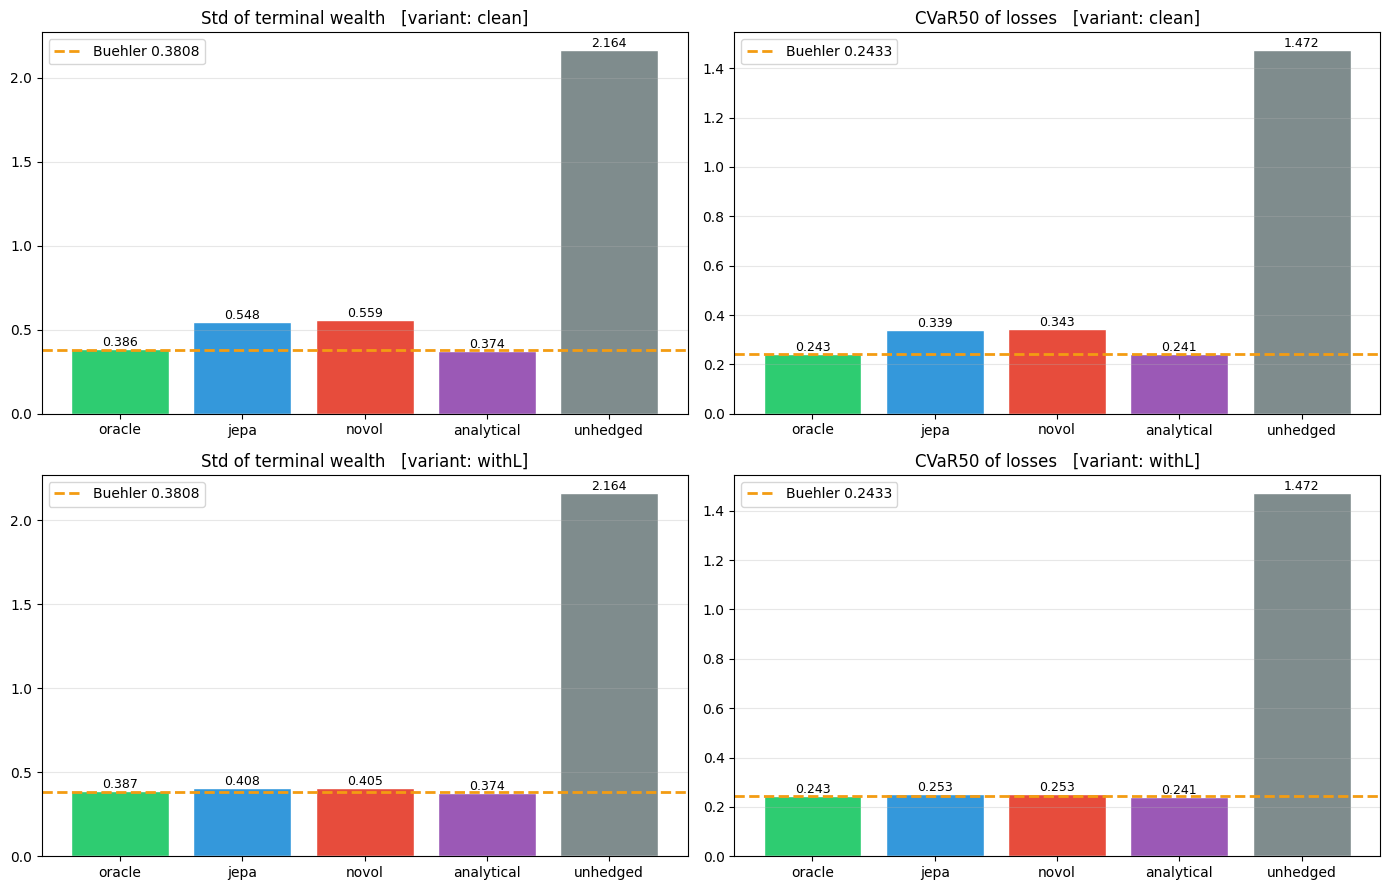

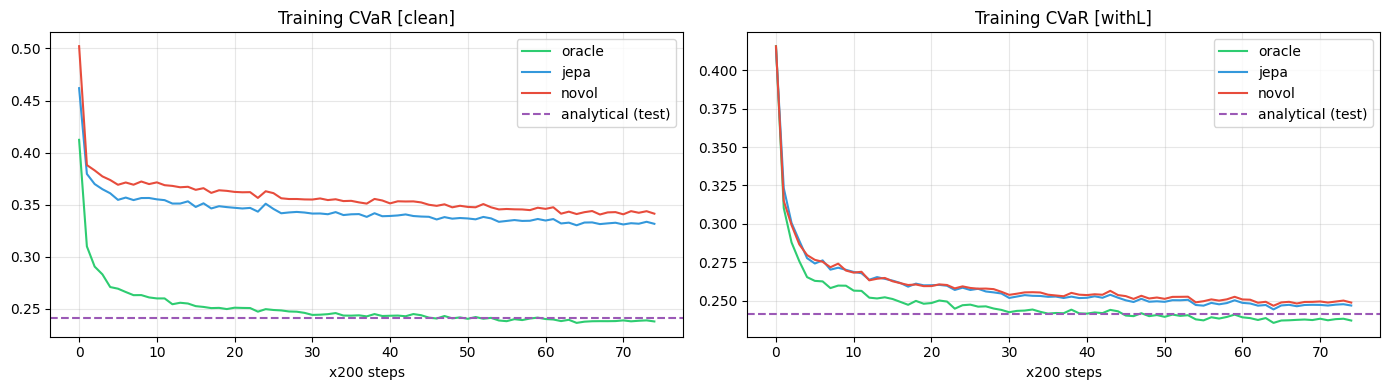

In [8]:
fig, axes = plt.subplots(len(VARIANTS), 2, figsize=(14, 4.5 * len(VARIANTS)), squeeze=False)
order = ['oracle', 'jepa', 'novol', 'analytical', 'unhedged']
cols = {'oracle': '#2ecc71', 'jepa': '#3498db', 'novol': '#e74c3c', 'analytical': '#9b59b6', 'unhedged': '#7f8c8d'}
for i, vname in enumerate(VARIANTS):
    rows = summary[vname]
    present = [o for o in order if o in rows]
    for j, (metric, ref, title) in enumerate([('std', BUEHLER_STD, 'Std of terminal wealth'),
                                              ('cvar', BUEHLER_CVAR, f'CVaR{int(ALPHA*100)} of losses')]):
        ax = axes[i, j]
        vals = [rows[o][metric] for o in present]
        bars = ax.bar(present, vals, color=[cols[o] for o in present], edgecolor='white')
        ax.axhline(ref, color='#f39c12', ls='--', lw=2, label=f'Buehler {ref}')
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v, f'{v:.3f}', ha='center', va='bottom', fontsize=9)
        ax.set_title(f'{title}   [variant: {vname}]'); ax.legend(); ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.savefig(os.path.join(RESULTS, 'hedging_v3_bars.png'), dpi=150); plt.show()

fig, axes = plt.subplots(1, len(VARIANTS), figsize=(7 * len(VARIANTS), 4), squeeze=False)
for i, vname in enumerate(VARIANTS):
    ax = axes[0, i]
    for cond in CONDITIONS:
        p = os.path.join(RUNS, f'{vname}_{cond}_s{SEEDS[0]}_hist.npy')
        if os.path.exists(p): ax.plot(np.load(p), label=cond, color=cols[cond])
    ax.axhline(summary[vname]['analytical']['cvar'], color=cols['analytical'], ls='--', label='analytical (test)')
    ax.set_title(f'Training CVaR [{vname}]'); ax.set_xlabel('x200 steps'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(os.path.join(RESULTS, 'hedging_v3_training.png'), dpi=150); plt.show()